In [1]:
!pip install nashpy
!pip install egttools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 13.4 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import nashpy as nash
import egttools as egt
from egttools.analytical.utils import (calculate_gradients, find_roots, check_replicator_stability_pairwise_games, StochDynamics)
import matplotlib.pyplot as plt


## Solution 1.

Initially, we define a function that returns both the set of available actions and the corresponding payoff matrix.
The actions are represented as a NumPy array containing all possible strategies within the range $[L,H]$.
The payoff matrix is generated using a lambda function that evaluates the expected reward associated with each strategy pair.



In [3]:
def get_actions_and_payoffs(N : int, L: float, H: float,R: float):

    actions = np.array([i for i in range(L, H+1)])

    f = lambda a, b: np.where(a > b, b - R,
                   np.where(a == b, b, a + R))

    # actions[:, None] creates a column vector (Row Player's actions, a)
    # actions[None, :] creates a row vector (Column Player's actions, b)
    # The f function is applied element-wise to every a, b pair across the matrix,
    # resulting in the final payoffs[a, b] matrix.
    payoffs = f(actions[:, None], actions[None, :])


    return actions, payoffs

In [4]:
actions, payoffs = get_actions_and_payoffs(9, 2, 10, 1.9)

print(actions)
print(payoffs)

[ 2  3  4  5  6  7  8  9 10]
[[ 2.   3.9  3.9  3.9  3.9  3.9  3.9  3.9  3.9]
 [ 0.1  3.   4.9  4.9  4.9  4.9  4.9  4.9  4.9]
 [ 0.1  1.1  4.   5.9  5.9  5.9  5.9  5.9  5.9]
 [ 0.1  1.1  2.1  5.   6.9  6.9  6.9  6.9  6.9]
 [ 0.1  1.1  2.1  3.1  6.   7.9  7.9  7.9  7.9]
 [ 0.1  1.1  2.1  3.1  4.1  7.   8.9  8.9  8.9]
 [ 0.1  1.1  2.1  3.1  4.1  5.1  8.   9.9  9.9]
 [ 0.1  1.1  2.1  3.1  4.1  5.1  6.1  9.  10.9]
 [ 0.1  1.1  2.1  3.1  4.1  5.1  6.1  7.1 10. ]]


Now we need to define the game using the Nashpy library.
Since the game is symmetric, both players have the same payoff structure.
For this reason, the constructor receives the payoff matrix and its transpose as inputs.

In [5]:
game = nash.Game(payoffs, payoffs.T)
game

Bi matrix game with payoff matrices:

Row player:
[[ 2.   3.9  3.9  3.9  3.9  3.9  3.9  3.9  3.9]
 [ 0.1  3.   4.9  4.9  4.9  4.9  4.9  4.9  4.9]
 [ 0.1  1.1  4.   5.9  5.9  5.9  5.9  5.9  5.9]
 [ 0.1  1.1  2.1  5.   6.9  6.9  6.9  6.9  6.9]
 [ 0.1  1.1  2.1  3.1  6.   7.9  7.9  7.9  7.9]
 [ 0.1  1.1  2.1  3.1  4.1  7.   8.9  8.9  8.9]
 [ 0.1  1.1  2.1  3.1  4.1  5.1  8.   9.9  9.9]
 [ 0.1  1.1  2.1  3.1  4.1  5.1  6.1  9.  10.9]
 [ 0.1  1.1  2.1  3.1  4.1  5.1  6.1  7.1 10. ]]

Column player:
[[ 2.   0.1  0.1  0.1  0.1  0.1  0.1  0.1  0.1]
 [ 3.9  3.   1.1  1.1  1.1  1.1  1.1  1.1  1.1]
 [ 3.9  4.9  4.   2.1  2.1  2.1  2.1  2.1  2.1]
 [ 3.9  4.9  5.9  5.   3.1  3.1  3.1  3.1  3.1]
 [ 3.9  4.9  5.9  6.9  6.   4.1  4.1  4.1  4.1]
 [ 3.9  4.9  5.9  6.9  7.9  7.   5.1  5.1  5.1]
 [ 3.9  4.9  5.9  6.9  7.9  8.9  8.   6.1  6.1]
 [ 3.9  4.9  5.9  6.9  7.9  8.9  9.9  9.   7.1]
 [ 3.9  4.9  5.9  6.9  7.9  8.9  9.9 10.9 10. ]]

## Solution.2

According to this analysis, we reach a Nash Equilibrium when both players choose the first action (to 'write two'). So, with this stable strategy, the players don't maximize their expected payoffs because everyone obtains 0 as a payoff.

In my opinion, if you want to maximize your payoff, you need to execute your best response—which is to choose a low value—because, in the worst case, you draw, but in all other cases, you maximize your payoff.



In [6]:
equilibria = list(game.support_enumeration())


In [7]:
equilibria

[(array([1., 0., 0., 0., 0., 0., 0., 0., 0.]),
  array([1., 0., 0., 0., 0., 0., 0., 0., 0.]))]

# Solution.3


## 3.1
For the first part, we need to identify the set of stationary points.
To do this, we use the find_roots function, which searches for all points where the gradient (or derivative) of the function equals zero.
Once we obtain this set of points, we analyze each one to determine whether it represents a stable, saddle, or unstable point.

A stable point corresponds to an equilibrium in a dynamical system—this is conceptually similar to the Nash equilibrium identified in the first exercise.
The remaining strategies are classified as saddle points.
A saddle point represents a strategy that is locally stable in some directions but unstable in others; in other words, small perturbations can cause the system to move away from equilibrium in certain directions, as can be seen in the plot.







In [8]:

x = np.linspace(0, 1, num=len(actions), dtype=np.float64)
gradient_function = lambda x: egt.analytical.replicator_equation(x, payoffs)

roots = find_roots(gradient_function, nb_strategies=len(actions), nb_initial_random_points=0, method="hybr")
stability = check_replicator_stability_pairwise_games(roots, payoffs)

for i in stability:
  if i == 1:
    print(str(i) + " (STABLE POINT)")
  elif i == 0:
    print(str(i) + " (SADDLE POINT)")
  else:
    print(str(i) + " (UNSTABLE POINT)")


1 (STABLE POINT)
0 (SADDLE POINT)
0 (SADDLE POINT)
0 (SADDLE POINT)
0 (SADDLE POINT)
0 (SADDLE POINT)
0 (SADDLE POINT)
0 (SADDLE POINT)
0 (SADDLE POINT)


## 3.2

Based on this analysis, we observe that some strategies eventually disappear, while others stabilize at constant frequencies. The plot illustrates how the probability distribution of each strategy evolves over time.
In particular, we notice that one strategy maintains a significantly higher probability than the others, indicating that it is the dominant strategy most likely to be played as the system evolves.

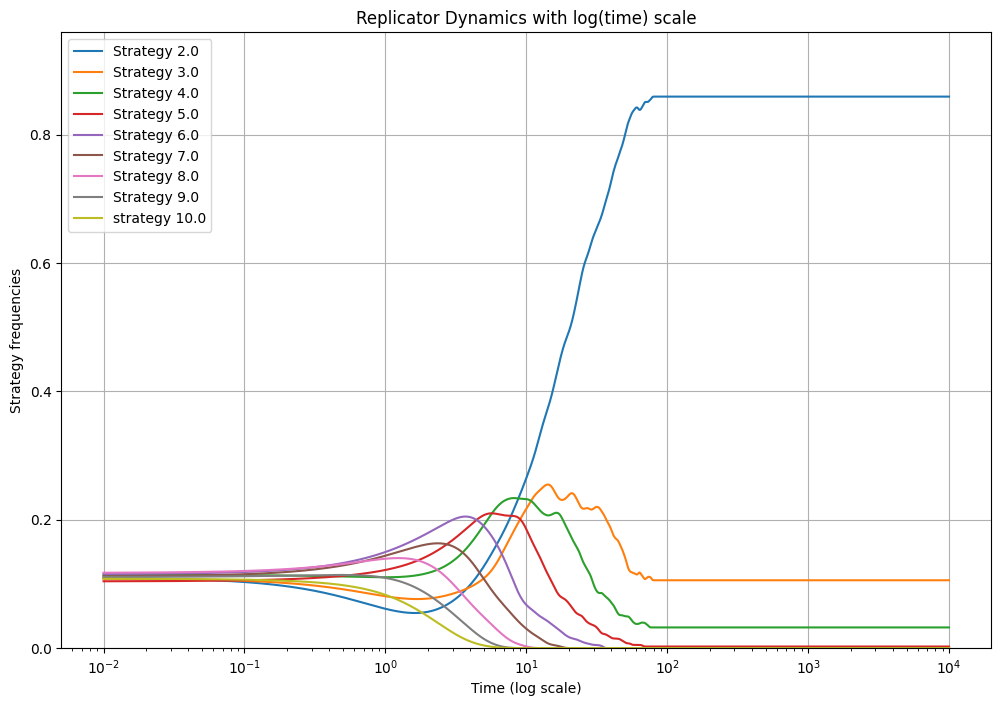

In [9]:

timepoints = np.logspace(-2, 4, 4000)
strategies = [[] for _ in range(9)]

for i in range(400):
    y0 = np.random.dirichlet(np.ones(len(actions)))
    evolution = np.array(list(game.replicator_dynamics(timepoints=timepoints, y0=y0)))

    for z, j in enumerate(evolution.T):
        strategies[z].append(j)

mean_strategies = [np.mean(np.array(y), axis=0) for y in strategies]
mean_strategies = np.array(mean_strategies).T



plt.figure(figsize=(12,8))
plt.plot(timepoints, mean_strategies)
plt.xscale("log")
plt.xlabel("Time (log scale)")
plt.ylabel("Strategy frequencies")
plt.title("Replicator Dynamics with log(time) scale")
plt.legend(["Strategy 2.0", "Strategy 3.0", "Strategy 4.0","Strategy 5.0","Strategy 6.0","Strategy 7.0","Strategy 8.0","Strategy 9.0", "strategy 10.0"])
if(np.round(np.max(mean_strategies),2) < 0.6):
  plt.ylim(-0.5,0.5)
else:
  plt.ylim(0,np.round(np.max(mean_strategies),2)+0.1)
plt.grid(True)
plt.show()


# Solution 4.

##4.1
For lower values of selection strength, all strategies tend to have approximately the same frequency — around 0.1 each. This indicates that selection pressure is weak, and random fluctuations dominate the dynamics.

##4.2
For higher values of selection strength, the first strategy becomes dominant throughout the evolution (as observed in the previous exercise), while the remaining strategies gradually disappear.

##4.3
At intermediate levels of selection strength, we observe a mixed behavior: strategies exhibit different probabilities because the dynamics initially favor some strategies over others, but no clear dominance emerges immediately.

##4.4
When we assume a finite population, the overall outcome remains consistent with the previous analysis: one dominant strategy (the first one) emerges, while the others diminish over time.






In [10]:
nb_strategies = 9; Z = 100;
evolver = StochDynamics(nb_strategies, payoffs, Z)

/usr/local/lib/python3.12/dist-packages/egttools/analytical/sed_analytical.py:749: RuntimeWarning: Some of the entries in the transition matrix are close to 1 (with a tolerance of 1e-11). This could result in more than one eigenvalue of magnitude 1 (the Markov Chain is degenerate), so please be careful when analysing the results.
  warn(


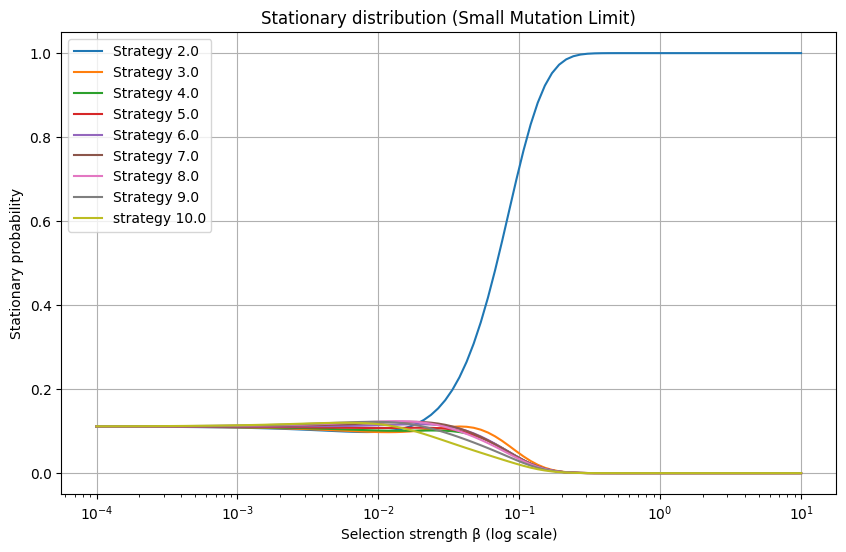

In [11]:


values = np.logspace(-4, 1, 100)
results = []

for beta in values:
    stationary_SML = evolver.calculate_stationary_distribution(beta)
    results.append(stationary_SML)

results = np.array(results)

# Plot
plt.figure(figsize=(10, 6))

for i in range(results.shape[1]):
    plt.plot(values, results[:, i])

plt.xscale("log")
plt.xlabel("Selection strength β (log scale)")
plt.ylabel("Stationary probability")
plt.title("Stationary distribution (Small Mutation Limit)")
plt.legend(["Strategy 2.0", "Strategy 3.0", "Strategy 4.0","Strategy 5.0","Strategy 6.0","Strategy 7.0","Strategy 8.0","Strategy 9.0", "strategy 10.0"])
plt.grid(True)
plt.show()





# Solution. 5

## 5.1 (Using $R = 1.1$)
The Replicator Dynamics analysis shows that the evolutionary stability of the first strategy is sensitive to changes in the payoff matrix. If the payoff for the first strategy, when paired with low-frequency opponents, is not sufficiently high, its frequency is quickly driven to zero.

This occurs because the payoff matrix is structured such that the first strategy's expected payoff (its fitness) is lower than the average population payoff, leading to negative frequency growth.

For an infinite population, the system is expected to converge to an Evolutionary Stable Strategy (ESS) or a Nash Equilibrium (NE), which may or may not involve the first strategy.

However, if the first strategy is risk-dominant or has a sufficiently large basin of attraction, the analysis in the small-mutation limit would show that this strategy is highly likely to be the long-term convention in the population.

## 5.2 (Using $R = 1.9$)

The average reward for the first strategy peaked transiently (around the midpoint of the simulation), achieving a high value while the performance of the alternative strategy steadily declined during the same period.

This phenomenon illustrates the powerful impact of payoff structure (reward setting) on the evolutionary dynamics of a system. It demonstrates that the Evolutionary Stable Strategy (ESS) may differ from the strategy that is risk-dominant or transiently most rewarding.




---


## I will declare that I used an LLM for coding assistance, as I am unfamiliar with programming in NumPy and plotting graphics with the matplotlib library, and to correct syntax and grammar errors in my written report.


---

